# The same shocks, unexpected: myopic expectations on the `new_fixed` planner model

`new_fixed_planner.ipynb` solves the planner's problem under **perfect foresight**. The
household's Euler equation

$$x_t=x_{t+1}-\tfrac1\gamma\big[i_t-\pi_{t+1}-r^n_t\big]$$

is iterated backwards from $t=T$, so at $t=0$ the household already knows the entire future
path of inflation, of the natural rate, and of its own consumption gap. The shock is fully
expected in the only sense the model allows: its whole continuation is priced in from the
moment it lands.

This notebook makes the shock **unexpected**. The shock still hits at $t=0$, but agents do
not see past the current period: each period they observe today's state and expect the
economy to be back at its steady state next period. Formally this is Gabaix's
behavioural-NK cognitive discounting with attention parameter $\lambda$: the perceived
deviation of any variable $\xi$ one period ahead is

$$\mathbb{E}^{BR}_t\,\xi_{t+1}=\lambda\,\mathbb{E}_t\,\xi_{t+1},$$

applied uniformly to $\pi_{t+1}$, to the household's own $x_{t+1}$, and to the exogenous
$z_{t+1}$ and $y^n_{t+1}$ that build the natural rate. $\lambda=1$ is perfect foresight and
reproduces `new_fixed_planner` **exactly**; $\lambda=0$ is the fully unexpected,
one-period-surprise case. The intermediate values are the interesting part: they show which
of the original notebook's results are properties of the model and which are properties of
foresight.

**Everything else is `new_fixed_planner`'s, unchanged** — the same calibration of $\tau_i$
from inventory/COGS data, the same corrected rate matrix, the same CES price index
$P=1/\tilde A$, the same physical-consumption convention, $\gamma=2$, the same $3\%$ TFP and
$1\%$ demand shocks. The only edit is to expectations.

One structural fact makes this a clean experiment: the firm side of the model is entirely
backward-looking. A firm delivering at $t$ discounts over $[t-\tau_i+1,\,t]$, all of it
realised, and its price $p_i=\text{markup}/(A_i\,\text{tprod}_i)$ contains no expectation of
anything. So $\lambda$ touches the Euler equation and nothing else, and every difference
below is attributable to the household's foresight alone. (Section 8 returns to the one
place where a forward-looking firm would matter.)

**The headline.** At $\lambda=0$ the planner's problem collapses: it attains the first best
exactly and in closed form, the demand shock's characteristic overshoot disappears, and the
gap attains at a finite horizon instead of decaying asymptotically in it. The entire content
of `new_fixed_planner`'s policy problem lives in
$\mathbb{E}_t\pi_{t+1}$ — kill expected inflation and time-to-produce stops constraining the
planner, even though the cost channel that produces the inflation is completely untouched.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to `new_fixed_planner.ipynb`, which is identical to `new_fixed.ipynb`.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 2.0
eta = 2.0
chi = 1.0
PHI_YA = (1 + eta) / (gamma + eta)

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

A_SHOCK = 0.97                   # 3 per cent TFP decline
D_SHOCK = 0.01                   # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, chi={chi}, rho={rho:.6f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')

gamma=2.0, eta=2.0, phi_ya=0.75, chi=1.0, rho=0.010000
A shock = 0.97 (3%),  demand shock = 1%


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)

print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')
print(f'tau ranges over [{tvals.min()}, {tvals.max()}];  counts by tau = {np.bincount(tvals)}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_24986/359100226.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269
tau ranges over [0, 13];  counts by tau = [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]


In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    '''Staggering matrix: which firms have re-optimised by period t.'''
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> TFP shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> TFP shock fully worked through by t = 15


## 2. The model, with expectations indexed by $\lambda$

`rate_matrix` and `aggregates` are `new_fixed_planner`'s verbatim — nothing on the firm or
price side changes, and it is worth being explicit about why. The discount block
$\text{disc}_t=\prod_{k=0}^{\tau_i-1}(1+i_{t-k})^{-1}$ reads only dates $\le t$, and physical
productivity
$Z_t=\big(\sum_i(Z^{\text{phys}}_i s_{it})^{\sigma-1}\big)^{1/(\sigma-1)}$ contains no rate at
all. The entire supply block is backward-looking, so $\lambda$ has exactly one point of entry.

**The behavioural Euler equation.** Substituting $\mathbb{E}^{BR}_t\xi_{t+1}=\lambda\xi_{t+1}$
into the household's optimality condition gives

$$x_t=\lambda\,x_{t+1}-\tfrac1\gamma\big[i_t-\lambda\pi_{t+1}-r^{n,BR}_t\big],
\qquad
r^{n,BR}_t=\rho-\underbrace{(\lambda z_{t+1}-z_t)}_{\text{perceived }\texttt{dem}_t}
+\gamma\underbrace{(\lambda y^n_{t+1}-y^n_t)}_{\text{perceived }\Delta y^n_t}.$$

The shrinkage has to be applied to the exogenous terms as well as to $\pi$ and $x$. Applying
it only to $\pi$ would leave a household that cannot see next period's inflation but can see
next period's productivity, which is not a consistent information set and would break the
$\lambda=1$ nesting. The assertion two cells down checks that nesting numerically.

Because $z$ and $y^n$ are normalised to zero at $T$ (the terminal steady state), "expect the
economy back at steady state next period" and "$\lambda=0$" are the same statement.

In [5]:
def rate_matrix(r, T=T, truncated=False):
    '''Row t = the rates a firm delivering at t discounts over, most recent lag first.'''
    r = np.asarray(r, float)
    L = len(r)
    if truncated:
        irl = np.ones((T, T)) * rho
        blk = np.full((L, L), rho, dtype=float)
        for i in range(L):
            blk[i, :i + 1] = r[i::-1]
        irl[0:L, :L] = blk
        return irl
    idx = np.subtract.outer(np.arange(T), np.arange(T))          # idx[t, k] = t - k
    return np.where((idx >= 0) & (idx < L), r[np.clip(idx, 0, L - 1)], rho)


def aggregates(r, T=T, a_shock=False, time_to_build=True, shock_ttb=None, truncated=False):
    '''(a_nat, d, pi): measured TFP, its discount content, and CES inflation.

    Unchanged from new_fixed_planner.  Note every term reads dates <= t, so nothing here
    depends on lambda -- the supply side of this model has no expectations in it.
    '''
    if shock_ttb is None:
        shock_ttb = time_to_build
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    disc = ce[:, tvals if time_to_build else np.zeros_like(tvals)]

    sm = np.ones((T, NFIRMS))
    if a_shock:
        if shock_ttb:
            sm[0:15] = A_PATTERN[1:]      # shock arrives in cohorts
        else:
            sm[0, :] = A_SHOCK            # every firm hit at once

    tprod = disc * Z_PHYS * sm
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))        # measured (cost) TFP
    Z_t = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))  # physical

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])                 # P = 1 / Atil
    return a_nat, d, pi


def pref_shifter(dem):
    '''z_t implied by the demand shock: dem_t = z_{t+1} - z_t, normalised z_T = 0.'''
    dem = np.asarray(dem, float)
    return -np.cumsum(dem[::-1])[::-1]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
          truncated=False, natural_rate_dy=True, euler_on='physical', lam=1.0):
    '''Behavioural Euler equation, then consumption = gap + natural level.

    lam = 1  : perfect foresight, identical to new_fixed_planner.
    lam = 0  : the shock is unexpected -- each period the household expects the economy
               back at its steady state next period.
    '''
    a_nat, d, pi = aggregates(r, T, a_shock, time_to_build, shock_ttb, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    pi_fwd = np.r_[pi[1:], 0.0]

    a_phys_pre = a_nat - d
    y_nat = PHI_YA * (a_nat if euler_on == 'measured' else a_phys_pre)
    z = pref_shifter(dem)

    # E^BR_t xi_{t+1} = lam * xi_{t+1}, applied to z and y^n as well as to pi and x.
    # At lam = 1: lam*z_{t+1} - z_t == dem_t and lam*y_{t+1} - y_t == dy_t, so this
    # reduces to new_fixed_planner's r_nat exactly.
    z_fwd = np.r_[z[1:], 0.0]
    y_fwd = np.r_[y_nat[1:], 0.0]
    dem_e = lam * z_fwd - z
    dy_e = lam * y_fwd - y_nat
    r_nat = rho - dem_e + (gamma * dy_e if natural_rate_dy else 0.0)

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = lam * x[t + 1] - (1.0 / gamma) * (ip[t] - lam * pi_fwd[t] - r_nat[t])
    x = x[:T]

    a_phys = a_nat - d
    if euler_on == 'measured':
        c_meas = x + PHI_YA * a_nat         # discount still inside
        cc = c_meas - d
    else:
        cc = x + PHI_YA * a_phys            # the Euler holds on c itself
        c_meas = cc + d
    return dict(c=cc, c_meas=c_meas, x=x, pi=pi, a_nat=a_nat, d=d, i=ip,
                a_phys=a_phys, c_eff=PHI_YA * a_phys, r_nat=r_nat,
                zeta=z, lam=lam)


CASES = {'TFP shock (3%)':    dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}

### Check: $\lambda=1$ reproduces `new_fixed_planner` exactly

`solve_pf` below is `new_fixed_planner`'s Euler block copied verbatim. If the $\lambda$
generalisation is right, the two must agree to machine zero — not approximately — on an
arbitrary non-constant rate path, for both shocks.

In [6]:
def solve_pf(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
             truncated=False, natural_rate_dy=True, euler_on='physical'):
    '''new_fixed_planner.ipynb's solve(), verbatim, as the reference implementation.'''
    a_nat, d, pi = aggregates(r, T, a_shock, time_to_build, shock_ttb, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    pi_fwd = np.r_[pi[1:], 0.0]
    a_phys_pre = a_nat - d
    y_nat = PHI_YA * (a_nat if euler_on == 'measured' else a_phys_pre)
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + (gamma * dy if natural_rate_dy else 0.0)
    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]
    a_phys = a_nat - d
    if euler_on == 'measured':
        cc = x + PHI_YA * a_nat - d
    else:
        cc = x + PHI_YA * a_phys
    return dict(c=cc, x=x, r_nat=r_nat)


r_probe = np.array([0.004, 0.012, 0.009, 0.011, 0.0075])
print('lambda = 1 against new_fixed_planner, on a non-constant rate path:\n')
for nm, kw in CASES.items():
    for eo in ['physical', 'measured']:
        s1 = solve(r_probe, lam=1.0, euler_on=eo, **kw)
        s0 = solve_pf(r_probe, euler_on=eo, **kw)
        dc = np.max(np.abs(s1['c'] - s0['c']))
        dx = np.max(np.abs(s1['x'] - s0['x']))
        dr = np.max(np.abs(s1['r_nat'] - s0['r_nat']))
        print(f'   {nm:<20} euler_on={eo:<9}  max|dc| = {dc:.3e}   '
              f'max|dx| = {dx:.3e}   max|dr_nat| = {dr:.3e}')
        assert dc == 0.0 and dx == 0.0 and dr == 0.0, 'lambda = 1 does not nest'
print('\n   assertion passed: lambda = 1 is new_fixed_planner bit for bit.')

lambda = 1 against new_fixed_planner, on a non-constant rate path:

   TFP shock (3%)       euler_on=physical   max|dc| = 0.000e+00   max|dx| = 0.000e+00   max|dr_nat| = 0.000e+00
   TFP shock (3%)       euler_on=measured   max|dc| = 0.000e+00   max|dx| = 0.000e+00   max|dr_nat| = 0.000e+00
   Demand shock (1%)    euler_on=physical   max|dc| = 0.000e+00   max|dx| = 0.000e+00   max|dr_nat| = 0.000e+00
   Demand shock (1%)    euler_on=measured   max|dc| = 0.000e+00   max|dx| = 0.000e+00   max|dr_nat| = 0.000e+00

   assertion passed: lambda = 1 is new_fixed_planner bit for bit.


## 3. What an unexpected shock does to the household

At $\lambda=0$ the Euler equation stops being a recursion and becomes a single static
equation,

$$x_t=-\tfrac1\gamma\big[i_t-r^{n,BR}_t\big],
\qquad r^{n,BR}_t=\rho+z_t-\gamma\,\varphi_{ya}\,a^{\text{phys}}_t,$$

using $z^e_{t+1}=y^{n,e}_{t+1}=\pi^e_{t+1}=0$. Two consequences follow immediately and both
are visible in the table below.

**The TFP shock stops moving consumption at all under a fixed rate.** Set $i_t=\rho$. Then
$x_t=-\tfrac1\gamma(\rho-\rho+\gamma\varphi_{ya}a^{\text{phys}}_t)=-\varphi_{ya}a^{\text{phys}}_t
=-c^e_t$, so

$$c_t=x_t+\varphi_{ya}a^{\text{phys}}_t=0\quad\text{exactly, for every }t.$$

A myopic household that sees productivity fall today and expects it back tomorrow does the
textbook thing with a transitory income loss: it smooths straight through and does not cut
consumption at all. Since the efficient response *is* to cut, the gap is exactly $-c^e_t$ —
the entire efficient movement becomes a gap. That is what makes the unexpected TFP shock
$2.9\times$ worse than the expected one at a fixed rate.

Note the sign on the labour side, since it is easy to get backwards. $n_t=c_t-a^{\text{phys}}_t$
is *above* steady state in the trough under both $\lambda$ — the efficient response is itself
$+0.27\%$, because $\varphi_{ya}<1$ means consumption should fall by less than productivity.
Myopia does not flip that, it doubles it: at $\lambda=0$, $c_t=0$ forces
$n_t=-a^{\text{phys}}_t=+1.08\%$, against $+0.55\%$ under foresight. The unexpected shock makes
the household hold its consumption up by working substantially harder than it should.

**The demand shock is unaffected by $\lambda$ under a fixed rate.** The preference shock
lasts one period, so $z_{t+1}=0$ is both the true and the perceived value and
$\texttt{dem}^e_0=\texttt{dem}_0$; and with the rate pinned the discount block is constant, so
$\pi\equiv0$ and there is nothing to mis-forecast. Perfect foresight and myopia coincide to
machine zero. This shock only separates once the *planner* starts moving the rate — which is
section 5.

In [7]:
w = 9
print('rate fixed at rho.  gap c_t - c^e_t, per cent\n')
for nm, kw in CASES.items():
    print('=' * 92); print(nm); print('=' * 92)
    print(f'   {"t":<30}' + ''.join(f'{t:>{w}}' for t in range(8)))
    print('   ' + '-' * 84)
    s_pf = solve(np.ones(3) * rho, lam=1.0, **kw)
    s_my = solve(np.ones(3) * rho, lam=0.0, **kw)
    for lab, v in [('efficient          c^e_t', s_pf['c_eff']),
                   ('expected  (lam=1)  c_t', s_pf['c']),
                   ('UNEXPECTED(lam=0)  c_t', s_my['c']),
                   ('expected  (lam=1)  gap', s_pf['c'] - s_pf['c_eff']),
                   ('UNEXPECTED(lam=0)  gap', s_my['c'] - s_my['c_eff']),
                   ('inflation          pi_t', s_pf['pi'])]:
        print(f'   {lab:<30}' + ''.join(f'{100*v[t]:>{w}.4f}' for t in range(8)))
    g_pf = np.max(np.abs(s_pf['c'] - s_pf['c_eff']))
    g_my = np.max(np.abs(s_my['c'] - s_my['c_eff']))
    print(f'\n   peak |gap|:  expected {100*g_pf:.4f}%   unexpected {100*g_my:.4f}%'
          f'   ratio {g_my / g_pf if g_pf > 0 else float("nan"):.3f}')
    print(f'   max |c| under lam=0: {np.max(np.abs(s_my["c"])):.3e}'
          f'   (zero for the TFP shock: full smoothing)')
    print()

rate fixed at rho.  gap c_t - c^e_t, per cent

TFP shock (3%)
   t                                     0        1        2        3        4        5        6        7
   ------------------------------------------------------------------------------------
   efficient          c^e_t        -0.0082  -0.2525  -0.8102  -0.4964  -0.4114  -0.1334  -0.0085  -0.0173
   expected  (lam=1)  c_t          -0.0036  -0.1511  -0.5280  -0.3401  -0.2854  -0.0959  -0.0061  -0.0124
   UNEXPECTED(lam=0)  c_t           0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000
   expected  (lam=1)  gap           0.0045   0.1014   0.2822   0.1563   0.1260   0.0375   0.0024   0.0049
   UNEXPECTED(lam=0)  gap           0.0082   0.2525   0.8102   0.4964   0.4114   0.1334   0.0085   0.0173
   inflation          pi_t          0.0000   0.2949   0.7538  -0.3758  -0.1094  -0.3790  -0.1796   0.0126

   peak |gap|:  expected 0.2822%   unexpected 0.8102%   ratio 2.871
   max |c| under lam=0: 0.000e+00   (ze

## 4. Impulse responses

The efficient level $c^e_t=\varphi_{ya}a^{\text{phys}}_t$ is policy-free and
$\lambda$-free — physical productivity contains no rate and no expectation — so it is the
same dotted line in every panel and the comparison is clean.

In [8]:
H = 16
COLOURS = {'TFP shock (3%)': 'C0', 'Demand shock (1%)': 'C1'}
# expected vs unexpected is the comparison every panel makes, so it gets the colours --
# not the shock, which is already the figure title.  Several lines lie exactly on top of
# one another by construction (that is usually the result), so the ones underneath carry
# markers and the zero line is drawn faint to stay out of their way.
C_EXP, C_UNEXP = '#1f3b73', '#c0392b'


def compare_figure(name, tab_pf, tab_my, fname, suptitle=None, horizon=H):
    '''Consumption, gap against efficient, and the rate: expected vs unexpected.'''
    r_pf, s_pf, b_pf = tab_pf[name]
    r_my, s_my, b_my = tab_my[name]
    t = np.arange(horizon)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    coincide = float(np.max(np.abs(b_pf['c'] - b_my['c'])))

    ax = axes[0]
    ax.axhline(0, color='0.75', lw=0.9, zorder=0)
    ax.plot(t, 100 * b_pf['c'][:horizon], color=C_EXP, lw=2.4,
            label=r'expected, $i=\rho$')
    ax.plot(t, 100 * b_my['c'][:horizon], color=C_UNEXP, lw=2.4, marker='o', ms=3.5,
            label=r'UNEXPECTED, $i=\rho$')
    ax.plot(t, 100 * s_pf['c'][:horizon], color=C_EXP, lw=1.7, ls='--',
            label='expected, planner')
    ax.plot(t, 100 * s_my['c'][:horizon], color=C_UNEXP, lw=1.7, ls='--',
            label='UNEXPECTED, planner')
    ax.plot(t, 100 * s_pf['c_eff'][:horizon], color='k', lw=1.3, ls=':',
            label='efficient')
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$c_t$  (per cent)')
    ax.set_title('Consumption (physical)'); ax.legend(fontsize=8)
    if coincide < 1e-12:
        ax.annotate(f'the two fixed-rate paths coincide\nexactly (max diff {coincide:.0e})',
                    xy=(0.04, 0.06), xycoords='axes fraction', fontsize=8, color=C_UNEXP)

    ax = axes[1]
    ax.axhline(0, color='0.75', lw=0.9, zorder=0)
    ax.plot(t, 100 * (b_pf['c'] - b_pf['c_eff'])[:horizon], color=C_EXP, lw=2.4,
            label=r'expected, $i=\rho$')
    ax.plot(t, 100 * (b_my['c'] - b_my['c_eff'])[:horizon], color=C_UNEXP, lw=2.4,
            marker='o', ms=3.5, label=r'UNEXPECTED, $i=\rho$')
    ax.plot(t, 100 * (s_pf['c'] - s_pf['c_eff'])[:horizon], color=C_EXP, lw=1.7, ls='--',
            label='expected, planner')
    ax.plot(t, 100 * (s_my['c'] - s_my['c_eff'])[:horizon], color=C_UNEXP, lw=1.7, ls='--',
            label='UNEXPECTED, planner')
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$c_t-c^e_t$  (per cent)')
    ax.set_title('Gap against the efficient level'); ax.legend(fontsize=8)

    ax = axes[2]
    ax.axhline(100 * rho, color='0.75', lw=0.9, zorder=0)
    ax.step(t, 100 * b_my['r_nat'][:horizon], where='post', color='k', lw=2.6, ls='-',
            alpha=0.25, label=r'perceived $r^{n,BR}_t$, $\lambda=0$')
    ax.step(t, 100 * s_pf['i'][:horizon], where='post', color=C_EXP, lw=2.2, ls='--',
            label='expected, planner')
    ax.step(t, 100 * s_my['i'][:horizon], where='post', color=C_UNEXP, lw=2.2, ls='--',
            label='UNEXPECTED, planner')
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel('$i_t$  (per cent)')
    ax.set_title(r'Nominal rate chosen by the planner'
                 '\n' r'(unexpected path lies on $r^{n,BR}_t$: the closed form)',
                 fontsize=11)
    ax.legend(fontsize=8)

    fig.suptitle(name if suptitle is None else suptitle, fontsize=13)
    fig.tight_layout()
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(fname)}  ({os.path.getsize(fname)} bytes)')
    plt.show(); plt.close(fig)


print('figure helper defined; the figures are drawn in section 5 once the planner has run.')

figure helper defined; the figures are drawn in section 5 once the planner has run.


## 5. The planner's problem when the shock is unexpected

The objective is `new_fixed_planner`'s, unchanged:
$U=\sum_t\beta^t\zeta_t[u(C_t)-\chi v(N_t)]$ on the physical paths, with $N_t=C_t/A^{\text{phys}}_t$.
The planner maximises **true** welfare taking the household's behavioural rule as given; it
is not itself myopic.

**At $\lambda=0$ the problem has a closed-form solution.** The gap is
$c_t-c^e_t=x_t=-\tfrac1\gamma(i_t-r^{n,BR}_t)$, and $c^e_t$ is policy-free, so the planner
zeroes the gap period by period with

$$i^\star_t=\text{clip}\big(r^{n,BR}_t,\;0,\;5\%\big)
=\text{clip}\big(\rho+z_t-\gamma\varphi_{ya}a^{\text{phys}}_t,\;0,\;5\%\big).$$

There is no trade-off left. The rate reaches prices exactly as before — section 3 of
`new_fixed_planner` verified that channel over 13 periods and nothing here disables it — but
under the physical-consumption convention the price level touches consumption *only* through
$\mathbb{E}_t\pi_{t+1}$, and that term is now zero. The cost channel is alive and welfare-irrelevant.

The cell below does not assume this. It runs the same L-BFGS-B escalation as
`new_fixed_planner` and checks the numerical optimum against the closed form.

In [9]:
def welfare(s):
    '''Discounted utility on the PHYSICAL paths.  Returns (U, U_cons, U_labour).'''
    cc, a = s['c'], s['a_phys']
    disc = beta_hh ** np.arange(len(cc)) * np.exp(s['zeta'])
    Cc = np.exp(cc)
    Nl = np.exp(cc - a)
    uc = np.log(Cc) if abs(gamma - 1.0) < 1e-12 else Cc**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return (float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)),
            float(np.sum(disc * un)))


def cons_equivalent(U_alt, UC_base, UN_base):
    '''Permanent proportional consumption change worth U_alt - U_base.'''
    if abs(gamma - 1.0) < 1e-12:
        return float(np.exp((U_alt + UN_base - UC_base)
                            / np.sum(beta_hh ** np.arange(T))) - 1.0)
    return float(((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0)


SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]
BOUNDS = (0.0, 0.05)


def optimise(L, kw, lam=1.0, bounds=BOUNDS):
    '''Best of three starts, L free periods.'''
    def obj(r):
        return -welfare(solve(r, lam=lam, **kw))[0]
    best = None
    for seed in SEEDS:
        res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        if best is None or res.fun < best.fun:
            best = res
    return best.x.copy(), float(best.fun), solve(best.x, lam=lam, **kw)


def myopic_closed_form(L, kw):
    '''i*_t = clip(r^{n,BR}_t) -- valid only at lam = 0, euler_on = 'physical'.'''
    s = solve(np.ones(3) * rho, lam=0.0, **kw)
    return np.clip(s['r_nat'][:L], *BOUNDS)


L_GRID = [1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 18, 20]
hist = {}
for nm, kw in CASES.items():
    print('=' * 96); print(nm); print('=' * 96)
    print(f'{"L":>4}{"peak|gap| expected":>22}{"peak|gap| UNEXPECTED":>24}'
          f'{"U expected":>16}{"U unexpected":>16}')
    print('-' * 96)
    hist[nm] = {}
    for L in L_GRID:
        row = {}
        for lam in (1.0, 0.0):
            rr, ff, ss = optimise(L, kw, lam=lam)
            row[lam] = (rr, ff, ss)
        hist[nm][L] = row
        print(f'{L:>4}'
              f'{np.max(np.abs(row[1.0][2]["c"] - row[1.0][2]["c_eff"])):>22.3e}'
              f'{np.max(np.abs(row[0.0][2]["c"] - row[0.0][2]["c_eff"])):>24.3e}'
              f'{-row[1.0][1]:>16.9f}{-row[0.0][1]:>16.9f}')
    print()

TFP shock (3%)
   L    peak|gap| expected    peak|gap| UNEXPECTED      U expected    U unexpected
------------------------------------------------------------------------------------------------


   1             2.542e-03               8.102e-03   -34.782637259   -34.782842270
   2             1.940e-03               8.102e-03   -34.782628702   -34.782829588


   3             4.297e-04               4.964e-03   -34.782615249   -34.782699134


   4             3.085e-04               4.114e-03   -34.782614899   -34.782650910


   6             1.180e-04               1.853e-04   -34.782614644   -34.782614765


...

  12             5.028e-06               7.922e-09   -34.741113516   -34.741113516


  14             5.242e-07               7.922e-09   -34.741113516   -34.741113516


  16             3.455e-07               7.922e-09   -34.741113516   -34.741113516


  18             2.410e-07               7.922e-09   -34.741113516   -34.741113516


  20             1.480e-07               7.922e-09   -34.741113516   -34.741113516



In [10]:
print('the closed form, against the numerical optimum  (lambda = 0)\n')
for nm, kw in CASES.items():
    L = 16
    r_num = hist[nm][L][0.0][0]
    r_cf = myopic_closed_form(L, kw)
    s_cf = solve(r_cf, lam=0.0, **kw)
    print('=' * 96); print(nm); print('=' * 96)
    print(f'   closed form  i*[:6] = {np.round(r_cf[:6], 6)}')
    print(f'   L-BFGS-B     i [:6] = {np.round(r_num[:6], 6)}')
    print(f'   max |difference| over L = {L}: {np.max(np.abs(r_num - r_cf)):.3e}')
    print(f'   peak |gap|, closed form  : {np.max(np.abs(s_cf["c"] - s_cf["c_eff"])):.3e}')
    print(f'   peak |gap|, L-BFGS-B     : '
          f'{np.max(np.abs(hist[nm][L][0.0][2]["c"] - s_cf["c_eff"])):.3e}')
    # first best = the allocation with c == c_eff identically
    s_fb = dict(s_cf); s_fb['c'] = s_cf['c_eff'].copy()
    print(f'   U(planner)  = {welfare(s_cf)[0]:.12f}')
    print(f'   U(first best) = {welfare(s_fb)[0]:.12f}   difference {welfare(s_cf)[0] - welfare(s_fb)[0]:.3e}')
    print()

the closed form, against the numerical optimum  (lambda = 0)

TFP shock (3%)
   closed form  i*[:6] = [0.010163 0.015051 0.026204 0.019927 0.018228 0.012668]
   L-BFGS-B     i [:6] = [0.010163 0.015051 0.026204 0.019927 0.018228 0.012668]
   max |difference| over L = 16: 2.071e-07
   peak |gap|, closed form  : 0.000e+00
   peak |gap|, L-BFGS-B     : 1.035e-07
   U(planner)  = -34.782614608796
   U(first best) = -34.782614608796   difference 0.000e+00

Demand shock (1%)
   closed form  i*[:6] = [0.   0.01 0.01 0.01 0.01 0.01]
   L-BFGS-B     i [:6] = [0.   0.01 0.01 0.01 0.01 0.01]
   max |difference| over L = 16: 1.584e-08
   peak |gap|, closed form  : 0.000e+00
   peak |gap|, L-BFGS-B     : 7.922e-09
   U(planner)  = -34.741113516333
   U(first best) = -34.741113516333   difference 0.000e+00



In [11]:
W = 46
summary_pf, summary_my = {}, {}
L_FIG = 16
for nm, kw in CASES.items():
    for lam, tab in [(1.0, summary_pf), (0.0, summary_my)]:
        rr, ff, ss = hist[nm][L_FIG][lam]
        tab[nm] = (rr, ss, solve(np.ones(3) * rho, lam=lam, **kw))

for nm, kw in CASES.items():
    print('=' * 84); print(nm); print('=' * 84)
    for lab, tab, lam in [('expected   (lambda = 1)', summary_pf, 1.0),
                          ('UNEXPECTED (lambda = 0)', summary_my, 0.0)]:
        r_opt, s_opt, s_base = tab[nm]
        U_b, UC_b, UN_b = welfare(s_base)
        print(f'  {lab}')
        print(f'    {"peak |c - c_eff|, rate fixed at rho":<{W}}: '
              f'{np.max(np.abs(s_base["c"] - s_base["c_eff"])):.4e}')
        print(f'    {"peak |c - c_eff|, planner":<{W}}: '
              f'{np.max(np.abs(s_opt["c"] - s_opt["c_eff"])):.4e}')
        print(f'    {"welfare gain (consumption equivalent)":<{W}}: '
              f'{100 * cons_equivalent(welfare(s_opt)[0], UC_b, UN_b):+.6f}% of ss C')
        print(f'    {"optimal rate path i[:8], %":<{W}}: {np.round(100 * r_opt[:8], 4)}')
        print(f'    {"periods above rho":<{W}}: '
              f'{int(np.sum(r_opt > rho + 1e-9))} of {len(r_opt)}')
        print(f'    {"overshoot  max(i) - rho, pp":<{W}}: {100 * (np.max(r_opt) - rho):+.4f}')
        print(f'    {"on a bound of [0, 5%]":<{W}}: '
              f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print()

TFP shock (3%)
  expected   (lambda = 1)
    peak |c - c_eff|, rate fixed at rho           : 2.8224e-03
    peak |c - c_eff|, planner                     : 2.3353e-07
    welfare gain (consumption equivalent)         : +0.000099% of ss C
    optimal rate path i[:8], %                    : [0.8251 0.9983 1.298  1.0435 1.0591 0.9677 0.9782 1.0094]
    periods above rho                             : 7 of 16
    overshoot  max(i) - rho, pp                   : +0.2980
    on a bound of [0, 5%]                         : False
  UNEXPECTED (lambda = 0)
    peak |c - c_eff|, rate fixed at rho           : 8.1021e-03
    peak |c - c_eff|, planner                     : 1.0354e-07
    welfare gain (consumption equivalent)         : +0.000873% of ss C
    optimal rate path i[:8], %                    : [1.0163 1.5051 2.6204 1.9927 1.8228 1.2668 1.017  1.0346]
    periods above rho                             : 11 of 16
    overshoot  max(i) - rho, pp                   : +1.6204
    on a bound of [0

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_myopic_A.png  (179297 bytes)


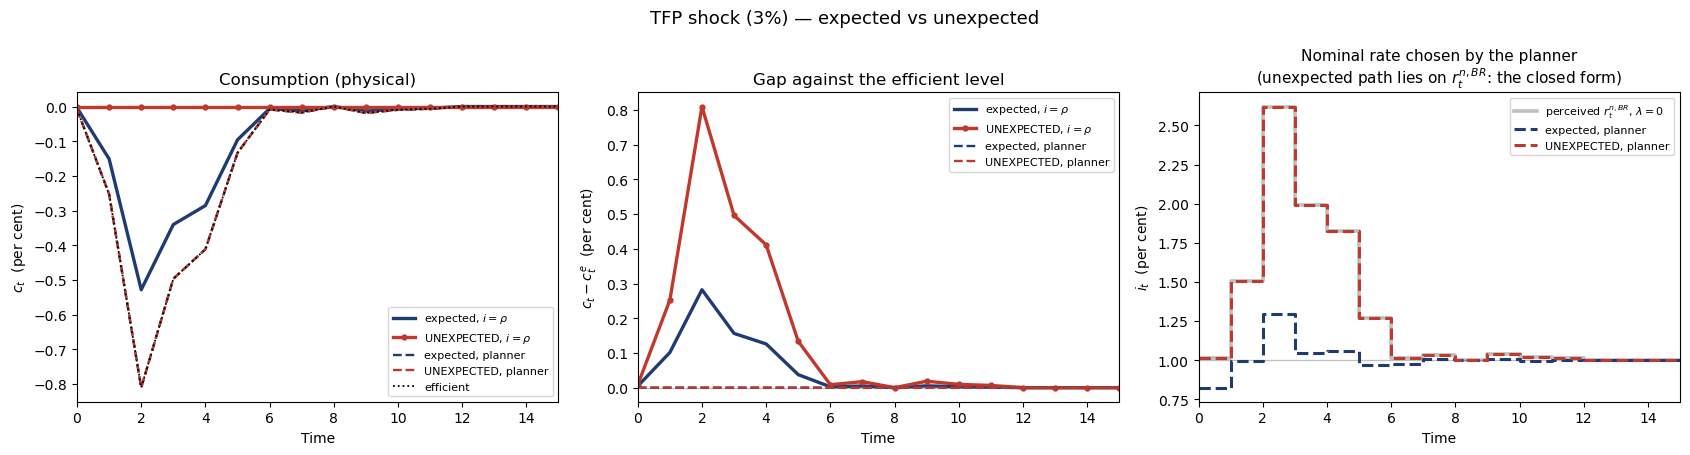

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_myopic_demand.png  (134459 bytes)


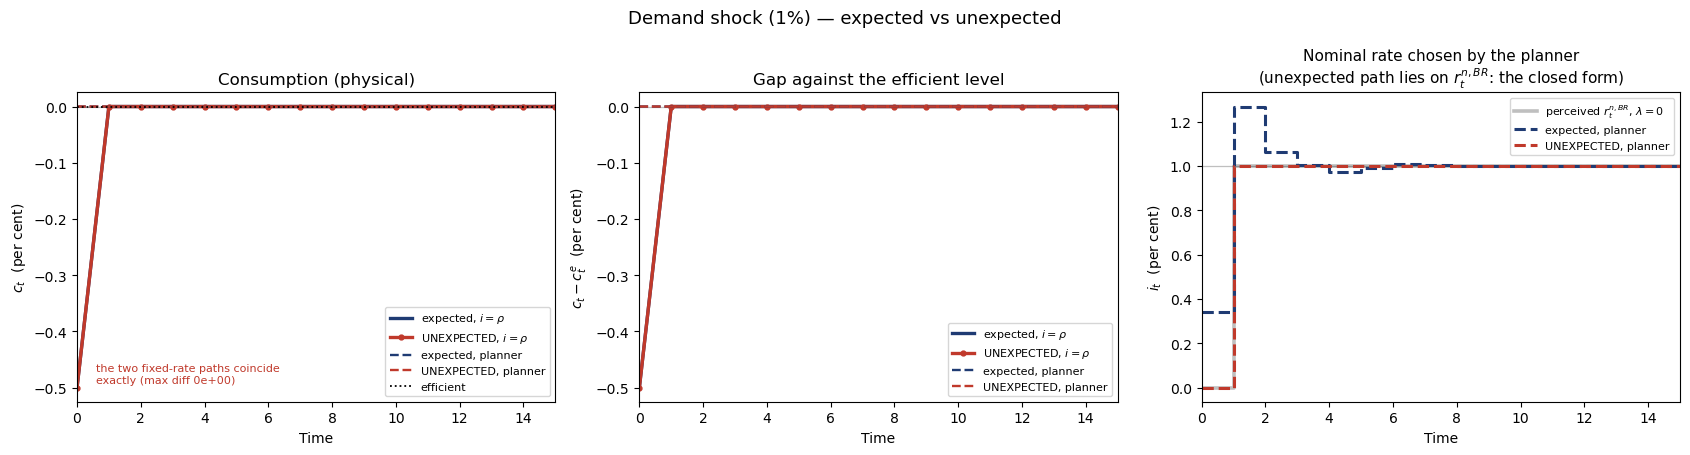

In [12]:
FN_A = '../semi_endo_new_fixed_planner_myopic_A.png'
FN_D = '../semi_endo_new_fixed_planner_myopic_demand.png'
compare_figure('TFP shock (3%)', summary_pf, summary_my, FN_A,
               suptitle='TFP shock (3%) — expected vs unexpected')
compare_figure('Demand shock (1%)', summary_pf, summary_my, FN_D,
               suptitle='Demand shock (1%) — expected vs unexpected')

Reading the figures.

* **TFP shock.** The red fixed-rate line sits flat on zero in the left panel — the myopic
  household does not cut consumption at all — so the whole of the efficient decline shows up
  as a gap in the middle panel, peaking at $0.81\%$ against $0.28\%$ under foresight. Both
  dashed planner lines lie on the efficient path, but only the unexpected one lies on it
  *exactly*. The unexpected-shock rate path in the third panel sits far higher — peaking at
  $2.62\%$ against $1.30\%$ — but that is a **level** effect and not an unwind: it is simply
  $r^{n,BR}_t=\rho-\gamma\varphi_{ya}a^{\text{phys}}_t$, which a household that reads a
  persistent productivity loss as transitory perceives as much higher than it is.
* **Demand shock.** The two fixed-rate lines coincide exactly: a one-period preference shock
  under a pinned rate has nothing to anticipate. The separation is entirely in the third
  panel — the expected-shock planner cuts to $0.34\%$ and then has to hike to $1.27\%$, while
  the unexpected-shock planner cuts to $0\%$ for exactly one period and returns to $\rho$.
* The dotted line in the third panel is the household's *perceived* natural rate
  $r^{n,BR}_t$. At $\lambda=0$ the red rate path lies on it, which is the closed form.

**Two results of `new_fixed_planner` are properties of foresight, not of the model.**

1. *The overshoot is gone.* `new_fixed_planner` reads its demand-shock path — $i_0=0.34\%$,
   then $i_1=1.27\%$ above $\rho$ — as the planner unwinding the deflation its own period-0
   cut pushes forward through $\beta^\tau$. The cut still pushes exactly that deflation here;
   the propagation is untouched. What is gone is the household's ability to *see* it coming,
   and with it the entire reason to unwind. The overshoot was never about the price path — it
   was about the expectation of the price path.

2. *The gap now attains rather than decaying.* `new_fixed_planner` reports geometric decay at
   $0.734$/$0.684$ per extra free period and no attainment at any finite $L$, because a move
   made to close the gap at $t$ also lands on $t+1,\dots,t+\tau_i$ with no second instrument
   to undo it. At $\lambda=0$ those spillovers land on the price level and stop there, so the
   planner has one instrument per target: the demand shock is closed exactly at $L=1$ (gap
   $\sim10^{-18}$) and the TFP shock once $L$ covers the cohort window.

## 6. In between: how much foresight does it take?

$\lambda$ interpolates, so the two results above can be traced continuously. The quantity to
watch for the demand shock is the overshoot $\max_t i_t-\rho$, which is $0$ at $\lambda=0$
and should grow monotonically into `new_fixed_planner`'s $+0.27$pp at $\lambda=1$.

In [13]:
LAMS = [0.0, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9, 1.0]
L_SWEEP = 14
sweep = {nm: {} for nm in CASES}
for nm, kw in CASES.items():
    print('=' * 100); print(nm); print('=' * 100)
    print(f'{"lambda":>8}{"peak|gap| fixed":>18}{"peak|gap| planner":>20}'
          f'{"i_0 %":>10}{"i_1 %":>10}{"overshoot pp":>15}{"CE gain %":>13}')
    print('-' * 100)
    for lam in LAMS:
        s_b = solve(np.ones(3) * rho, lam=lam, **kw)
        U_b, UC_b, UN_b = welfare(s_b)
        r_o, f_o, s_o = optimise(L_SWEEP, kw, lam=lam)
        rec = dict(gap_fixed=float(np.max(np.abs(s_b['c'] - s_b['c_eff']))),
                   gap_opt=float(np.max(np.abs(s_o['c'] - s_o['c_eff']))),
                   i0=float(r_o[0]), i1=float(r_o[1]),
                   overshoot=float(np.max(r_o) - rho),
                   ce=float(cons_equivalent(welfare(s_o)[0], UC_b, UN_b)),
                   r=r_o.copy())
        sweep[nm][lam] = rec
        print(f'{lam:>8.2f}{rec["gap_fixed"]:>18.3e}{rec["gap_opt"]:>20.3e}'
              f'{100*rec["i0"]:>10.4f}{100*rec["i1"]:>10.4f}'
              f'{100*rec["overshoot"]:>15.4f}{100*rec["ce"]:>13.6f}')
    print()

TFP shock (3%)
  lambda   peak|gap| fixed   peak|gap| planner     i_0 %     i_1 %   overshoot pp    CE gain %
----------------------------------------------------------------------------------------------------


    0.00         8.102e-03           1.035e-07    1.0163    1.5051         1.6204     0.000873


    0.10         7.907e-03           3.850e-06    1.0498    1.5596         1.5315     0.000846


    0.25         7.565e-03           4.912e-06    1.1061    1.5914         1.3515     0.000795


    0.40         7.119e-03           2.637e-06    1.1425    1.5513         1.1250     0.000725


...

    0.50         5.000e-03           3.856e-07    0.1406    1.1850         0.1850     0.000189


    0.60         5.000e-03           4.209e-07    0.1819    1.2122         0.2122     0.000189


    0.75         5.000e-03           3.769e-07    0.2443    1.2422         0.2422     0.000189


    0.90         5.000e-03           4.235e-07    0.3035    1.2608         0.2608     0.000189


    1.00         5.000e-03           5.242e-07    0.3402    1.2681         0.2681     0.000189



wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_myopic_lambda.png  (132359 bytes)


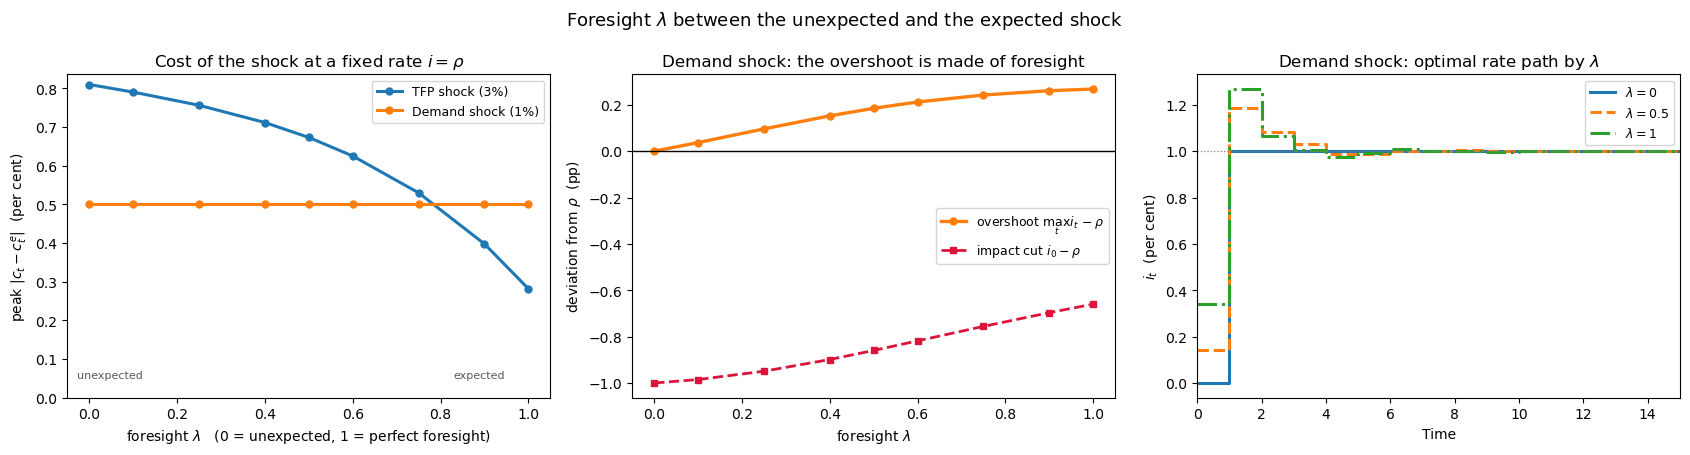

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
lams = np.array(LAMS)

ax = axes[0]
for nm in CASES:
    ax.plot(lams, [100 * sweep[nm][l]['gap_fixed'] for l in LAMS], 'o-',
            color=COLOURS[nm], lw=2.2, ms=5, label=nm)
ax.set_xlabel(r'foresight $\lambda$   (0 = unexpected, 1 = perfect foresight)')
ax.set_ylabel(r'peak $|c_t-c^e_t|$  (per cent)')
ax.set_title(r'Cost of the shock at a fixed rate $i=\rho$')
ax.set_ylim(bottom=0)
ax.annotate('unexpected', xy=(0.02, 0.06), xycoords='axes fraction', fontsize=8,
            color='0.35')
ax.annotate('expected', xy=(0.80, 0.06), xycoords='axes fraction', fontsize=8,
            color='0.35')
ax.legend(fontsize=9)

ax = axes[1]
nm = 'Demand shock (1%)'
ax.plot(lams, [100 * sweep[nm][l]['overshoot'] for l in LAMS], 'o-', color=COLOURS[nm],
        lw=2.4, ms=5, label=r'overshoot $\max_t i_t-\rho$')
ax.plot(lams, [100 * (sweep[nm][l]['i0'] - rho) for l in LAMS], 's--', color='crimson',
        lw=2.0, ms=5, label=r'impact cut $i_0-\rho$')
ax.axhline(0, color='k', lw=1.0)
ax.set_xlabel(r'foresight $\lambda$')
ax.set_ylabel('deviation from $\\rho$  (pp)')
ax.set_title('Demand shock: the overshoot is made of foresight')
ax.legend(fontsize=9)

ax = axes[2]
t = np.arange(H)
for lam, sty in [(0.0, '-'), (0.5, '--'), (1.0, '-.')]:
    ip = np.ones(T) * rho
    ip[:L_SWEEP] = sweep[nm][lam]['r']
    ax.step(t, 100 * ip[:H], where='post', lw=2.2, ls=sty,
            label=rf'$\lambda={lam:g}$')
ax.axhline(100 * rho, color='grey', lw=0.9, ls=':')
ax.set_xlim(0, H - 1)
ax.set_xlabel('Time'); ax.set_ylabel('$i_t$  (per cent)')
ax.set_title('Demand shock: optimal rate path by $\\lambda$')
ax.legend(fontsize=9)

fig.suptitle(r'Foresight $\lambda$ between the unexpected and the expected shock', fontsize=13)
fig.tight_layout()
out = '../semi_endo_new_fixed_planner_myopic_lambda.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print(f'wrote {os.path.abspath(out)}  ({os.path.getsize(out)} bytes)')
plt.show(); plt.close(fig)

## 7. Where the collapse stops: the lower bound

The $\lambda=0$ first best is attained only because $i^\star_t=r^{n,BR}_t$ happens to be
feasible. For the demand shock $r^{n,BR}_0=\rho-D$, so a shock larger than $\rho=1\%$ drives
the required rate negative and the planner is stuck at the bound with a residual gap of
exactly

$$c_0-c^e_0=-\tfrac1\gamma\big(0-(\rho-D)\big)=-\tfrac{D-\rho}{\gamma}.$$

The calibrated $D=1\%$ sits precisely on the boundary — $r^{n,BR}_0=0$ exactly — which is a
coincidence of the calibration, not a property of the model, and worth knowing before the
"planner attains the first best" line is quoted anywhere.

In [15]:
print('demand shock size vs the lower bound  (lambda = 0, L = 8)\n')
print(f'{"D shock %":>11}{"r^{n,BR}_0 %":>15}{"i_0 chosen %":>15}{"peak |gap| %":>15}'
      f'{"predicted %":>14}{"at bound":>10}')
print('-' * 80)
for D in [0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03]:
    kwd = dict(a_shock=False, demand=np.r_[D, np.zeros(T - 1)])
    s_b = solve(np.ones(3) * rho, lam=0.0, **kwd)
    r_o, f_o, s_o = optimise(8, kwd, lam=0.0)
    pred = max(0.0, (D - rho) / gamma)
    print(f'{100*D:>11.3f}{100*s_b["r_nat"][0]:>15.4f}{100*r_o[0]:>15.4f}'
          f'{100*np.max(np.abs(s_o["c"] - s_o["c_eff"])):>15.5f}{100*pred:>14.5f}'
          f'{str(bool(np.isclose(r_o[0], 0.0, atol=1e-9))):>10}')
print('\n   the "predicted" column is (D - rho)/gamma, the bound-constrained closed form.')

demand shock size vs the lower bound  (lambda = 0, L = 8)

  D shock %   r^{n,BR}_0 %   i_0 chosen %   peak |gap| %   predicted %  at bound
--------------------------------------------------------------------------------


      0.250         0.7500         0.7500        0.00000       0.00000     False


      0.500         0.5000         0.5000        0.00002       0.00000     False
      0.750         0.2500         0.2500        0.00000       0.00000     False


      1.000         0.0000         0.0000        0.00000       0.00000      True
      1.250        -0.2500         0.0000        0.12500       0.12500      True


      1.500        -0.5000         0.0000        0.25000       0.25000      True
      2.000        -1.0000         0.0000        0.50000       0.50000      True


      3.000        -2.0000         0.0000        1.00000       1.00000      True

   the "predicted" column is (D - rho)/gamma, the bound-constrained closed form.


## 8. Two things this experiment does not settle

**(a) The collapse is specific to the physical-consumption convention.** Under
`euler_on='physical'` — `new_fixed_planner`'s default, and the one it argues for — the rate
reaches consumption only through $\pi_{t+1}$, which is why zeroing expected inflation zeroes
the planner's trade-off. Under `euler_on='measured'` consumption carries an extra
$-(1-\varphi_{ya})d_t$ term, and $d_t$ (the discount content of measured TFP) *does* depend on
the rate path directly. The planner then still faces a genuine trade-off at $\lambda=0$, and
in fact a worse one. So "unexpected shocks make the planner's job easy" is a statement about
the valuation convention before it is a statement about expectations.

**(b) Firms here do not forecast rates, and a fully behavioural model would make them.** The
supply block is backward-looking as implemented: a firm delivering at $t$ discounts over
realised rates $[t-\tau_i+1,\,t]$. But a firm *starting* production at $s$ with lag $\tau_i$
commits its price at $s$, when $i_{s+1},\dots,i_{s+\tau_i-1}$ are still in the future. Under
foresight it is consistent to have priced them in; under $\lambda=0$ it is not — a myopic
firm would price off $i_s$ and then $\rho$, which would sharply weaken the section-3 cost
channel. That is a second, separate channel for "unexpected", it cuts in the same direction
as this one, and it is left for a follow-up rather than silently mixed in here. The
$\lambda=0$ numbers below are therefore best read as an upper bound on how much of the cost
channel survives an unexpected shock.

In [16]:
print("euler_on = 'measured': does myopia still collapse the planner's problem?\n")
print(f'{"case":<20}{"lambda":>8}{"gap fixed":>14}{"gap planner":>14}   i[:4] %')
print('-' * 88)
for nm, kw in CASES.items():
    for lam in (1.0, 0.0):
        kw2 = dict(kw, euler_on='measured')
        s_b = solve(np.ones(3) * rho, lam=lam, **kw2)
        r_o, f_o, s_o = optimise(14, kw2, lam=lam)
        print(f'{nm:<20}{lam:>8.1f}{np.max(np.abs(s_b["c"]-s_b["c_eff"])):>14.3e}'
              f'{np.max(np.abs(s_o["c"]-s_o["c_eff"])):>14.3e}   {np.round(100*r_o[:4], 4)}')
print("\n   under 'measured' the lam = 0 planner gap is larger than the lam = 1 one, not zero:")
print('   the collapse in sections 5-6 is a property of the physical convention.')

euler_on = 'measured': does myopia still collapse the planner's problem?

case                  lambda     gap fixed   gap planner   i[:4] %
----------------------------------------------------------------------------------------


TFP shock (3%)           1.0     2.579e-03     1.614e-04   [1.3002 0.5947 1.0928 1.0068]


TFP shock (3%)           0.0     7.859e-03     6.466e-04   [1.1236 0.2282 0.7365 1.095 ]


Demand shock (1%)        1.0     5.000e-03     2.732e-04   [0.1331 0.7721 0.8827 0.8114]


Demand shock (1%)        0.0     5.000e-03     1.553e-03   [1.7133 0.     1.8537 0.336 ]

   under 'measured' the lam = 0 planner gap is larger than the lam = 1 one, not zero:
   the collapse in sections 5-6 is a property of the physical convention.


## Summary

`new_fixed_planner`'s model, calibration and objective, with one edit: the household no
longer sees the shock coming. $\lambda=1$ reproduces that notebook bit for bit (section 2's
assertion), $\lambda=0$ is the unexpected shock.

1. **An unexpected TFP shock moves consumption not at all under a fixed rate.** At
   $\lambda=0$, $x_t=-c^e_t$ identically, so $c_t\equiv0$ to machine zero. The household
   treats a 13-period cohort-staggered productivity decline as a one-period income dip and
   smooths straight through it. The efficient path falls to $-0.81\%$, so the entire
   efficient movement becomes a gap: the unexpected shock is $2.9\times$ costlier than the
   expected one at an unchanged rate. Labour is above steady state in the trough either way —
   the efficient response is itself $+0.27\%$ — but myopia doubles the excess, to
   $n_t=-a^{\text{phys}}_t=+1.08\%$ against $+0.55\%$ under foresight.

2. **An unexpected demand shock is indistinguishable from an expected one under a fixed
   rate.** The preference shock lasts one period and a pinned rate leaves $\pi\equiv0$, so
   there is nothing to mis-forecast; the two paths agree to machine zero. Expectations only
   start to matter once the planner moves the rate.

3. **The planner attains the first best exactly, in closed form.** At $\lambda=0$ the gap is
   static in $i_t$, so $i^\star_t=\text{clip}(\rho+z_t-\gamma\varphi_{ya}a^{\text{phys}}_t)$
   zeroes it period by period. L-BFGS-B, run blind, recovers this to $\sim2\times10^{-7}$, and
   the closed form's welfare matches the literal first best — $c_t$ replaced by $c^e_t$ by hand
   — to every printed digit. The welfare gain over an unchanged rate is $8.8\times$ larger than
   under foresight for the TFP shock ($+0.00087\%$ against $+0.00010\%$ of steady-state
   consumption), simply because there is $2.9\times$ more gap to close.

4. **The demand-shock overshoot is made entirely of foresight.** `new_fixed_planner` cuts to
   $0.34\%$ and then hikes to $1.27\%$, and reads the hike as unwinding the deflation its own
   cut pushes forward through $\beta^{\tau}$. The cut pushes exactly the same deflation here —
   the cost channel is untouched, section 3's 13-period propagation is intact — but with
   $\mathbb{E}_t\pi_{t+1}=0$ there is nothing to unwind, and the path is $i_0=0\%$ for one
   period and $\rho$ thereafter. The $\lambda$ sweep shows the overshoot growing monotonically
   from $0$ to $+0.27$pp as foresight is restored.

   One thing not to misread: for the *TFP* shock the $\lambda=0$ rate path is higher than the
   $\lambda=1$ one, $\max_t i_t-\rho=+1.62$pp against $+0.30$pp. That is not an overshoot in
   the same sense. It is the level of the perceived natural rate $r^{n,BR}_t$, which myopia
   raises because a transitory-looking productivity loss implies a steeply rising consumption
   profile. The two statistics share a formula and mean different things.

5. **The horizon result changes character.** `new_fixed_planner` finds geometric decay at
   $0.734$/$0.684$ per free period and no attainment at finite $L$, because a move made for
   date $t$ also lands on $t+1,\dots,t+\tau_i$ and there is no second instrument. At
   $\lambda=0$ the spillovers still land, but on a price level that no longer enters welfare:
   the demand shock is closed exactly at $L=1$ and the TFP shock once $L$ covers the cohort
   window. Attainment, not decay.

6. **Read together, 4 and 5 say the same thing.** Under the physical-consumption convention
   the nominal rate reaches welfare only through expected inflation. Time to produce
   generates the inflation, but it constrains the planner only through the household's
   foresight of it. That is the sharpest available statement of what
   `new_fixed_planner`'s policy problem is actually made of — and it was not visible from
   inside that notebook, because $\lambda$ was fixed at 1.

7. **Two caveats, in section 8.** The collapse is specific to `euler_on='physical'`; under
   the measured convention the $\lambda=0$ planner is left with a *larger* gap than the
   $\lambda=1$ one. And the first best is attained only where the bound permits: at the
   calibrated $D=1\%$ the required $i_0$ is exactly $0$, so any larger demand shock leaves a
   residual gap of $(D-\rho)/\gamma$. The calibration sits precisely on that boundary.

8. **Firms are still backward-looking here.** They discount over realised rates, so $\lambda$
   enters through the Euler equation alone and every number above is attributable to
   household foresight. Making the firm's *pricing* decision myopic too is a separate channel
   pushing the same way; section 8(b) sets it out.